# Linear Models

This tutorial can be deployed in [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChemAI-Lab/Math4Chem/blob/main/website/Lecture_Notes/Notes/Coding/answers/linear_models.ipynb)

In this tutorial we will review **linear models**, which are the basic structure for many data-driven models. <br>

First, we will define the **mean square error function** for a linear model as, 

$$
{\cal L}(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^N \left (\hat{y}_i -  f(x_i,a,b) \right )^2  =  \frac{1}{N}\sum_{i=1}^N \left (\hat{y}_i - ( a\,x_i + b) \right )^2, 
$$
where $\mathbf{w}$ is the vector that contains the parameters of the linear model. For a simple linear model, 
$$
f(\mathbf{x}) = \mathbf{w}^\top \mathbf{x} = a\,x + b,
$$ 
where $\mathbf{w}$ only has two elements, $\mathbf{w}^\top = [a,b]$.


In [108]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import Button, FloatSlider, HBox, IntSlider, VBox, interact, interactive_output
from IPython.display import display

In [109]:
# generate random data over f(x) = sin(x) + x - 1
def get_data(N):
    # This creates an array x of N linearly spaced values between -1 and 1.
    x = np.linspace(-1., 1., N)
    y = np.sin(.5*x) + x - 1.
    # Adds random noise to each y value.
    y = y + np.random.uniform(low=0., high=1.2, size=x.shape)
    return x, y

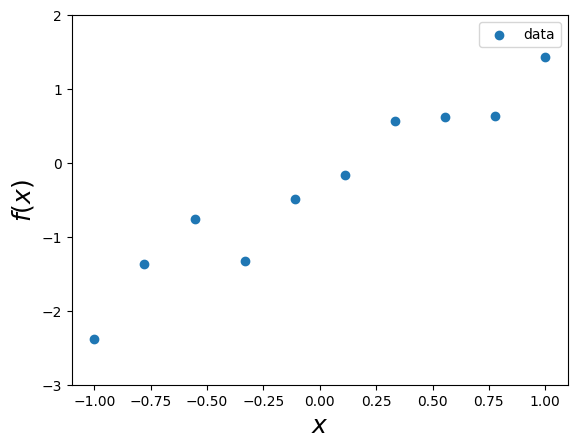

In [110]:
N = 10  # number of data points
x, y = get_data(N)

# plot
plt.scatter(x, y, label='data')
plt.xlabel(r'$x$', fontsize=18)
plt.ylabel(r'$f(x)$', fontsize=18)
plt.ylim(-3., 2.)
plt.legend()

In [111]:
def rmse(y, y_true):
    return np.mean((y - y_true)**2)

In [112]:
# Data
# x, y = get_data(25)
X = np.column_stack([np.ones_like(x), x])  # [1; x]

# Dense grid for the model line
x_grid = np.linspace(-1.0, 1.0, 400)
X_grid = np.column_stack([np.ones_like(x_grid), x_grid])


def linear_model(X, w):
    # w = [b, m]  -> y = b + m*x = [b,m] @ [1; x]
    return X @ w


# Grid over parameters
a = np.linspace(-2., 3.5, 200)  # slope
b = np.linspace(-2.5, 2.5, 200)  # intercept

A, B = np.meshgrid(a, b)
a_ = A.flatten()
b_ = B.flatten()

errors = []
for mi, bi in zip(a_, b_):
    w = np.array([[bi], [mi]])
    y_pred = linear_model(X, np.array([bi, mi]))
    error = rmse(y_pred, y)  # compute error for each (bi,mi)
    errors.append(error)

# reshape errors to grid
errors = np.array(errors).reshape(A.shape)

# ---- Plot function (like your draw(n=...)) ----


def draw(b=0.0, m=0.0):
    y_pred = linear_model(X_grid, np.array([b, m]))

    fig = plt.figure(figsize=(18, 5), constrained_layout=True)
    ax_data = fig.add_subplot(1, 3, 1)
    ax_error = fig.add_subplot(1, 3, 2)
    ax_surface = fig.add_subplot(1, 3, 3)

    ax_data.scatter(x, y, label='data', alpha=0.9)
    ax_data.plot(x_grid, y_pred, label='model', color='k', linewidth=2)
    # Vertical segments show the residual for every data point.
    ax_data.vlines(x, y, linear_model(X, np.array([b, m])),
                   color='tab:red', alpha=0.65, linewidth=1.5, label='error')
    ax_data.set_xlabel('x')
    ax_data.set_ylabel('y')
    ax_data.set_title('Model and pointwise errors')
    ax_data.legend()
    ax_data.text(0.97, 0.04, f"b={b:.2f}, m={m:.2f}",
                  transform=ax_data.transAxes, fontsize=12,
                  ha='right', va='bottom',
                  bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))

    residuals = linear_model(X, np.array([b, m])) - y
    absolute_points = ax_error.scatter(x, np.abs(residuals), marker='o',
                                      color='tab:orange')
    squared_points = ax_error.scatter(x, residuals**2, marker='s',
                                     color='tab:purple')
    ax_error.set_xlabel('x')
    ax_error.set_ylabel('error')
    ax_error.set_title('Pointwise error values')
    ax_error.grid(alpha=0.25)
    ax_error.legend([absolute_points, squared_points],
                   [r'$|\epsilon(x)|$', r'$\epsilon(x)^2$'],
                   loc='upper left')

    # Color shows the mean squared error for each (b, m).
    surface = ax_surface.contourf(B, A, errors, levels=60, cmap='viridis')
    current_error = rmse(linear_model(X, np.array([b, m])), y)
    ax_surface.scatter([b], [m], color='red', s=80,
                       edgecolor='white', linewidth=1.2,
                       label=f'current: error={current_error:.3f}')
    ax_surface.set_xlabel('b (intercept)')
    ax_surface.set_ylabel('m (slope)')
    ax_surface.set_title('Error map')
    fig.colorbar(surface, ax=ax_surface, shrink=0.65, pad=0.12,
                 label='mean squared error')
    ax_surface.legend()
    # constrained_layout keeps the 3D labels and colorbar inside the figure.


# ---- Widgets and optimal-parameter button ----
b_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                       description='b', continuous_update=False)
m_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                       description='m', continuous_update=False)

# The optimum here is the lowest-error point in the displayed grid.
best_index = np.unravel_index(np.argmin(errors), errors.shape)
optimal_b = float(B[best_index])
optimal_m = float(A[best_index])

optimal_button = Button(description='Set optimal parameters',
                         button_style='success',
                         tooltip='Move b and m to the lowest-error grid point')

def set_optimal_parameters(_):
    b_slider.value = optimal_b
    m_slider.value = optimal_m

optimal_button.on_click(set_optimal_parameters)
plot_output = interactive_output(draw, {'b': b_slider, 'm': m_slider})
display(VBox([HBox([b_slider, m_slider, optimal_button]), plot_output]))

## Seeing only the grid values of the MSE

This is a copy of the interactive panel above. Here, the error map is drawn with scatter points instead of filled contours. Each colored point is one MSE evaluation on the parameter grid; values between points have not been evaluated.

In [113]:
def draw_grid_points(b=0.0, m=0.0, n_grid=20):
    x_grid = np.linspace(-1.0, 1.0, 400)
    X_grid = np.column_stack([np.ones_like(x_grid), x_grid])

    # Rebuild the parameter mesh whenever n_grid changes.
    b_values = np.linspace(-2.5, 2.5, n_grid)
    m_values = np.linspace(-2., 3.5, n_grid)
    B_grid, A_grid = np.meshgrid(b_values, m_values)
    grid_predictions = (B_grid[..., None] + A_grid[..., None] * x[None, None, :])
    grid_errors = np.mean((grid_predictions - y[None, None, :]) ** 2, axis=2)

    y_pred = linear_model(X_grid, np.array([b, m]))
    fig = plt.figure(figsize=(18, 5), constrained_layout=True)
    ax_data = fig.add_subplot(1, 3, 1)
    ax_error = fig.add_subplot(1, 3, 2)
    ax_grid = fig.add_subplot(1, 3, 3)

    ax_data.scatter(x, y, label='data', alpha=0.9)
    ax_data.plot(x_grid, y_pred, label='model', color='k', linewidth=2)
    ax_data.vlines(x, y, linear_model(X, np.array([b, m])),
                   color='tab:red', alpha=0.65, linewidth=1.5, label='error')
    ax_data.set_xlabel('x')
    ax_data.set_ylabel('y')
    ax_data.set_title('Model and pointwise errors')
    ax_data.legend()
    ax_data.text(0.97, 0.04, f"b={b:.2f}, m={m:.2f}",
                  transform=ax_data.transAxes, fontsize=12,
                  ha='right', va='bottom',
                  bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))

    residuals = linear_model(X, np.array([b, m])) - y
    absolute_points = ax_error.scatter(x, np.abs(residuals), marker='o',
                                      color='tab:orange')
    squared_points = ax_error.scatter(x, residuals**2, marker='s',
                                     color='tab:purple')
    ax_error.set_xlabel('x')
    ax_error.set_ylabel('error')
    ax_error.set_title('Pointwise error values')
    ax_error.grid(alpha=0.25)
    ax_error.legend([absolute_points, squared_points],
                   [r'$|\epsilon(x)|$', r'$\epsilon(x)^2$'],
                   loc='upper left')

    # One colored point for every evaluated (b, m) grid location.
    points = ax_grid.scatter(B_grid.ravel(), A_grid.ravel(),
                            c=grid_errors.ravel(), cmap='viridis',
                            s=18, alpha=0.75)
    current_error = rmse(linear_model(X, np.array([b, m])), y)
    ax_grid.scatter([b], [m], color='red', s=180, edgecolor='black',
                    linewidth=1.2, label=f'current: error={current_error:.3f}')
    ax_grid.set_xlabel('b (intercept)')
    ax_grid.set_ylabel('m (slope)')
    ax_grid.set_title(f'MSE evaluated at {n_grid} × {n_grid} grid points')
    fig.colorbar(points, ax=ax_grid, label='mean squared error')
    ax_grid.legend()

b_grid_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                            description='b', continuous_update=False)
m_grid_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                            description='m', continuous_update=False)
n_grid_slider = IntSlider(value=10, min=5, max=60, step=5,
                          description='grid points', continuous_update=False)
grid_optimal_button = Button(description='Set optimal parameters',
                             button_style='success')

def set_grid_optimal_parameters(_):
    b_values = np.linspace(-2.5, 2.5, n_grid_slider.value)
    m_values = np.linspace(-2., 3.5, n_grid_slider.value)
    B_grid, A_grid = np.meshgrid(b_values, m_values)
    grid_predictions = B_grid[..., None] + A_grid[..., None] * x[None, None, :]
    grid_errors = np.mean((grid_predictions - y[None, None, :]) ** 2, axis=2)
    best = np.unravel_index(np.argmin(grid_errors), grid_errors.shape)
    b_grid_slider.value = float(B_grid[best])
    m_grid_slider.value = float(A_grid[best])

grid_optimal_button.on_click(set_grid_optimal_parameters)
grid_output = interactive_output(draw_grid_points,
    {'b': b_grid_slider, 'm': m_grid_slider, 'n_grid': n_grid_slider})
display(VBox([HBox([b_grid_slider, m_grid_slider, n_grid_slider,
                  grid_optimal_button]), grid_output]))

# Polynomial fitting  
Let's consider, 
$$
f(\mathbf{w}, x)  = \mathbf{w}^\top \mathbf{x}
 = \begin{bmatrix}
w_0 & w_1 & & w_2 \\
\end{bmatrix}\begin{bmatrix}
 1 \\
 x \\
 x^2
\end{bmatrix} = w_2 \,x^2  + w_1 \,x + w_0
$$

**Goal**: Find the value of $\mathbf{w}$ where ${\cal L}$ has the lowest value. 
For a quadratic polynomial, 
$$
{\cal L}(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^N \left (\hat{y}_i -  f(x_i,\mathbf{w}) \right )^2  =  \frac{1}{N}\sum_{i=1}^N \left (\hat{y}_i - ( w_2 \,x^2  + w_1 \,x + w_0) \right )^2, 
$$


In [ ]:
# Use a separate, visibly curved dataset for the quadratic example.
rng_quad = np.random.default_rng(7)
y_quad = 0.8 * x**2 + 0.4 * x - 1.0
y_quad = y_quad + rng_quad.normal(0.0, 0.2, size=x.shape)

# Quadratic model: y = w0 + w1*x + w2*x**2
X_quad = np.column_stack([np.ones_like(x), x, x**2])
x_quad_grid = np.linspace(-1.0, 1.0, 400)
X_quad_grid = np.column_stack([np.ones_like(x_quad_grid),
                               x_quad_grid, x_quad_grid**2])

w0_values = np.linspace(-2.5, 2.5, 100)
w1_values = np.linspace(-2.5, 2.5, 100)
w2_values = np.linspace(-2.5, 2.5, 100)

def quadratic_model(X, w):
    return X @ np.asarray(w)

def pair_error(first_values, second_values, fixed_name, fixed_value):
    first, second = np.meshgrid(first_values, second_values)
    if fixed_name == 'w2':
        predictions = first[..., None] + second[..., None] * x + fixed_value * x**2
    elif fixed_name == 'w1':
        predictions = first[..., None] + fixed_value * x + second[..., None] * x**2
    else:  # fixed w0
        predictions = fixed_value + first[..., None] * x + second[..., None] * x**2
    return first, second, np.mean((predictions - y_quad) ** 2, axis=2)

def draw_quadratic(w0=0.0, w1=0.0, w2=0.0):
    w = np.array([w0, w1, w2])
    y_pred = quadratic_model(X_quad_grid, w)
    current_error = rmse(quadratic_model(X_quad, w), y_quad)

    fig = plt.figure(figsize=(15, 5), constrained_layout=True)
    ax_data = fig.add_subplot(1, 3, 1)
    ax02 = fig.add_subplot(1, 3, 2)
    ax12 = fig.add_subplot(1, 3, 3)

    ax_data.scatter(x, y_quad, label='quadratic data', alpha=0.9)
    ax_data.plot(x_quad_grid, y_pred, color='k', linewidth=2, label='quadratic model')
    ax_data.vlines(x, y_quad, quadratic_model(X_quad, w), color='tab:red',
                   alpha=0.65, linewidth=1.5, label='error')
    ax_data.set(xlabel='x', ylabel='y', title='Quadratic model')
    ax_data.text(0.97, 0.04, f'w0={w0:.2f}, w1={w1:.2f}, w2={w2:.2f}',
                 transform=ax_data.transAxes, ha='right', va='bottom',
                 bbox=dict(facecolor='white', alpha=0.75, edgecolor='none'))
    ax_data.legend()

    W0b, W2, E02 = pair_error(w0_values, w2_values, 'w1', w1)
    W1, W2b, E12 = pair_error(w1_values, w2_values, 'w0', w0)
    for ax, Xg, Yg, E, xlabel, ylabel, title, px, py in [
        (ax02, W0b, W2, E02, 'w0', 'w2', f'w0-w2 (w1={w1:.2f})', w0, w2),
        (ax12, W1, W2b, E12, 'w1', 'w2', f'w1-w2 (w0={w0:.2f})', w1, w2),
    ]:
        contours = ax.contourf(Xg, Yg, E, levels=40, cmap='viridis')
        ax.scatter([px], [py], color='red', edgecolor='white', s=70)
        ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
        fig.colorbar(contours, ax=ax, shrink=0.8, label='MSE')

w0_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                        description='w0', continuous_update=False)
w1_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                        description='w1', continuous_update=False)
w2_slider = FloatSlider(value=0.0, min=-2.5, max=2.5, step=0.01,
                        description='w2', continuous_update=False)
quadratic_optimal_button = Button(description='Set optimal parameters',
                                  button_style='success')

def set_quadratic_optimal_parameters(_):
    optimal_w = np.linalg.lstsq(X_quad, y_quad, rcond=None)[0]
    w0_slider.value = float(np.clip(optimal_w[0], -2.5, 2.5))
    w1_slider.value = float(np.clip(optimal_w[1], -2.5, 2.5))
    w2_slider.value = float(np.clip(optimal_w[2], -2.5, 2.5))

quadratic_optimal_button.on_click(set_quadratic_optimal_parameters)
quadratic_output = interactive_output(draw_quadratic,
    {'w0': w0_slider, 'w1': w1_slider, 'w2': w2_slider})
display(VBox([HBox([w0_slider, w1_slider, w2_slider,
                  quadratic_optimal_button]), quadratic_output]))